# SpendDNA: Spotify Wrapped for Your Money

**Name:** Spandana Nadagouda  
**Roll Number:** UNXRNSIT-1235  
**Batch:** October 2026  
**Technology:** Python, Pandas and NumPy

## Project Overview
SpendDNA analyses six months of synthetic bank transactions to understand spending habits, identify spending patterns, detect unusual transactions, and discover spending archetypes.

## Objectives
- Clean and standardise transaction data.
- Extract and classify vendors.
- Categorise transactions.
- Analyse spending and savings.
- Identify monthly and time-of-day patterns.
- Detect unusual transactions.
- Discover spending archetypes.
- Generate meaningful insights from the data.

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime

df = pd.read_csv("/content/rahul_transactions.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Number of rows: 1328
Number of columns: 8

Column names:
['Date', 'Time', 'Description', 'Type', 'Amount', 'Balance', 'Mode', 'Ref']

First 5 rows:


,Date,Time,Description,Type,Amount,Balance,Mode,Ref
0,2024-01-01,03:11,AMAZON SELLER SVCS,Debit,₹2462,678275.0,UPI,TXN190872
1,01-Jan-24,05:44,BHIM-BMTC,DR,50.00,681007.0,UPI,TXN143064
2,01-Jan-24,09:35,NEFT-TECHCRUSH LABS-SALARY MAY24,CR,₹84728,484728.0,NEFT,TXN246316
3,2024-01-01,14:07,UPI-AMAN-8934@OKAXIS,Debit,₹1828,-748745.0,UPI,TXN569226
4,01 Jan 2024,14:23,BHIM-BLINKIT,Debit,270.00,680737.0,UPI,TXN968962


In [2]:

# Step 3: Check dataset information

print("Dataset Information:")
df.info()

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         1328 non-null   object 
 1   Time         1328 non-null   object 
 2   Description  1328 non-null   object 
 3   Type         1328 non-null   object 
 4   Amount       1328 non-null   object 
 5   Balance      1328 non-null   float64
 6   Mode         1328 non-null   object 
 7   Ref          1328 non-null   object 
dtypes: float64(1), object(7)
memory usage: 83.1+ KB

Missing Values in Each Column:
Date           0
Time           0
Description    0
Type           0
Amount         0
Balance        0
Mode           0
Ref            0
dtype: int64

Duplicate Rows:
18


In [3]:

# Step 4: Display all column names

for col in df.columns:
    print(col)


Date
Time
Description
Type
Amount
Balance
Mode
Ref


In [4]:
# Step 5: Display duplicate rows

duplicates = df[df.duplicated()]

print("Number of duplicate rows:", len(duplicates))
display(duplicates)

Number of duplicate rows: 18


,Date,Time,Description,Type,Amount,Balance,Mode,Ref
92,13 Jan 2024,19:40,BHIM-BLINKIT,DR,306.00,608435.0,UPI,TXN829168
122,18 Jan 2024,10:22,TUMMOC-BMTC,Debit,45,586624.0,UPI,TXN943700
149,22/01/24,19:12,UPI-IOC9075@HDFCBANK,Debit,"7,264.00",-378160.0,UPI,TXN734252
282,09-Feb-24,16:13,POS ZEPTO BANGALORE,Debit,Rs. 617,465428.0,UPI,TXN574514
372,2024-02-21,12:28,TUMMOC-BMTC,DR,25.00,401150.0,UPI,TXN427270
476,05 Mar 2024,21:33,UPI-AMAZONPAY@HDFCBANK,Debit,"19,917.00",-465439.0,UPI,TXN674071
568,18-Mar-24,13:44,Swiggy*Order,DR,₹383,247011.0,UPI,TXN346249
806,20/04/24,23:03,Swiggy*Order,Debit,Rs. 559,46778.0,UPI,TXN176523
816,2024-04-21,20:28,ZOMATO BENGALURU,DR,Rs. 682,43697.0,UPI,TXN274169
965,2024-05-12,20:55,POS SWIGGY BANGALORE,DR,615,-45370.0,UPI,TXN390956


In [5]:
# Step 6: Display the first 10 rows

display(df.head(10))

,Date,Time,Description,Type,Amount,Balance,Mode,Ref
0,2024-01-01,03:11,AMAZON SELLER SVCS,Debit,₹2462,678275.0,UPI,TXN190872
1,01-Jan-24,05:44,BHIM-BMTC,DR,50.00,681007.0,UPI,TXN143064
2,01-Jan-24,09:35,NEFT-TECHCRUSH LABS-SALARY MAY24,CR,₹84728,484728.0,NEFT,TXN246316
3,2024-01-01,14:07,UPI-AMAN-8934@OKAXIS,Debit,₹1828,-748745.0,UPI,TXN569226
4,01 Jan 2024,14:23,BHIM-BLINKIT,Debit,270.00,680737.0,UPI,TXN968962
5,2024-01-01,14:48,BHIM ZEPTO,DR,Rs. 625,677650.0,UPI,TXN370902
6,2024-01-01,14:50,UPI-UBER-2426@HDFCBANK,Debit,Rs. 148,677020.0,UPI,TXN546173
7,01-Jan-24,21:44,BHIM-BLINKIT,Debit,₹482,677168.0,UPI,TXN599219
8,2024-01-02,05:18,POS SWIGGY BANGALORE,Debit,Rs. 537,676177.0,UPI,TXN293319
9,02/01/24,06:55,UPI-GROWWPAY@HDFCBANK,DR,3956,672221.0,UPI,TXN418594


In [6]:
# Step 7: Check duplicate transaction reference numbers

print("Duplicate reference numbers:")
print(df[df["Ref"].duplicated(keep=False)].sort_values("Ref"))

Duplicate reference numbers:
             Date   Time              Description   Type     Amount   Balance  \
1170     09/06/24  07:09     POS SWIGGY BANGALORE  Debit    Rs. 232 -220615.0   
1169     09/06/24  07:09     POS SWIGGY BANGALORE  Debit    Rs. 232 -220615.0   
806      20/04/24  23:03             Swiggy*Order  Debit    Rs. 559   46778.0   
805      20/04/24  23:03             Swiggy*Order  Debit    Rs. 559   46778.0   
1059   2024-05-25  11:39   UPI-UBER-4781@HDFCBANK     DR        482 -131018.0   
484    2024-03-06  22:21    UPI-VIKAS-5416@OKAXIS  Debit   1,860.00 -701388.0   
815    2024-04-21  20:28         ZOMATO BENGALURU     DR    Rs. 682   43697.0   
816    2024-04-21  20:28         ZOMATO BENGALURU     DR    Rs. 682   43697.0   
1145     06/06/24  11:09   UPI-ZOMATO5117@OKICICI     DR    Rs. 649 -196117.0   
1146     06/06/24  11:09   UPI-ZOMATO5117@OKICICI     DR    Rs. 649 -196117.0   
567     18-Mar-24  13:44             Swiggy*Order     DR       ₹383  247011.0   

In [7]:
# Step 8: Count transaction types

print("Transaction types:")
print(df["Type"].value_counts())

print("\nTransaction modes:")
print(df["Mode"].value_counts())

Transaction types:
Type
DR       670
Debit    652
CR         6
Name: count, dtype: int64

Transaction modes:
Mode
UPI     1299
ATM       17
NEFT       6
IMPS       6
Name: count, dtype: int64


In [8]:

# Step 9: Remove exact duplicate rows

print("Rows before removing duplicates:", len(df))

df = df.drop_duplicates()

print("Rows after removing duplicates:", len(df))

print("Remaining duplicates:", df.duplicated().sum())


Rows before removing duplicates: 1328
Rows after removing duplicates: 1310
Remaining duplicates: 0


In [9]:

# Step 10: Check missing values

print(df.isnull().sum())


Date           0
Time           0
Description    0
Type           0
Amount         0
Balance        0
Mode           0
Ref            0
dtype: int64


In [10]:

# Step 11: Clean the Amount column

df["Amount"] = (
    df["Amount"]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True)
)

df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")

print(df["Amount"].head(10))
print("\nAmount data type:")
print(df["Amount"].dtype)


0     2462.000
1       50.000
2    84728.000
3     1828.000
4      270.000
5        0.625
6        0.148
7      482.000
8        0.537
9     3956.000
Name: Amount, dtype: float64

Amount data type:
float64


In [11]:

# Step 12: Check cleaned Amount values

print("Missing amounts:", df["Amount"].isnull().sum())
print("\nAmount summary:")
print(df["Amount"].describe())


Missing amounts: 0

Amount summary:
count     1310.000000
mean      1297.421559
std       5752.903503
min          0.100000
25%         24.000000
50%        366.500000
75%        690.000000
max      85492.000000
Name: Amount, dtype: float64


In [12]:

# Step 13: Clean the Balance column

df["Balance"] = (
    df["Balance"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(r"[^\d.-]", "", regex=True)
)

df["Balance"] = pd.to_numeric(df["Balance"], errors="coerce")

print(df["Balance"].head(10))
print("\nBalance data type:")
print(df["Balance"].dtype)


0    678275.0
1    681007.0
2    484728.0
3   -748745.0
4    680737.0
5    677650.0
6    677020.0
7    677168.0
8    676177.0
9    672221.0
Name: Balance, dtype: float64

Balance data type:
float64


In [13]:

# Step 14: Summary of account balances

print("Missing balances:", df["Balance"].isnull().sum())
print("\nBalance summary:")
print(df["Balance"].describe())


Missing balances: 0

Balance summary:
count      1310.000000
mean     149658.238931
std      339818.582531
min     -769127.000000
25%     -100791.000000
50%      154151.500000
75%      448566.750000
max      720079.000000
Name: Balance, dtype: float64


In [14]:

# Step 15: Standardize transaction types

df["Type"] = df["Type"].replace({
    "DR": "Debit",
    "CR": "Credit"
})

print(df["Type"].value_counts())


Type
Debit     1304
Credit       6
Name: count, dtype: int64


In [15]:

# Step 16: Clean payment modes

df["Mode"] = df["Mode"].str.strip().str.upper()

print("Payment mode counts:")
print(df["Mode"].value_counts())


Payment mode counts:
Mode
UPI     1281
ATM       17
NEFT       6
IMPS       6
Name: count, dtype: int64


In [16]:

# Step 17: Total amount by transaction type

print(df.groupby("Type")["Amount"].agg(["count", "sum", "mean"]))


        count           sum          mean
Type                                     
Credit      6  4.250738e+05  70845.641168
Debit    1304  1.274548e+06    977.414414


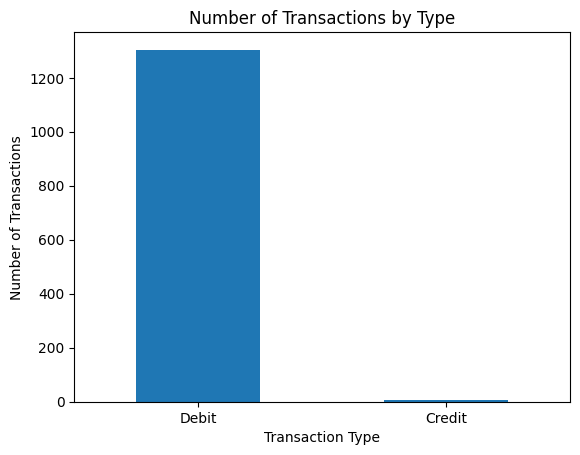

In [17]:

# Step 18: Plot transaction counts

import matplotlib.pyplot as plt

df["Type"].value_counts().plot(kind="bar")

plt.title("Number of Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()


Mode
UPI     1281
ATM       17
NEFT       6
IMPS       6
Name: count, dtype: int64


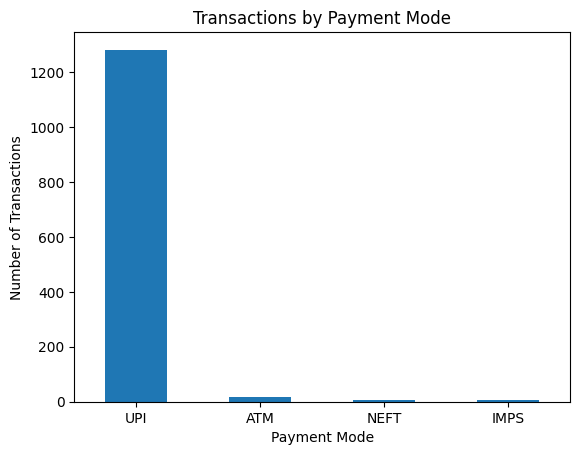

In [18]:

# Step 19: Transactions by Payment Mode

mode_counts = df["Mode"].value_counts()

print(mode_counts)

mode_counts.plot(kind="bar")
plt.title("Transactions by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()


In [19]:

# Step 20: Top 10 Transaction Descriptions

print(df["Description"].value_counts().head(10))


Description
SWIGGY-INSTAMART         29
POS SWIGGY BANGALORE     28
ZOMATO MEDIA P L         26
Swiggy*Order             26
UPI-RAPIDO@OKAXIS        24
POS SWIGGY-RESTAURANT    24
POS ZOMATO               23
BHIM SWIGGY              23
ZOMATO BENGALURU         22
OLA CABS                 21
Name: count, dtype: int64


In [20]:

# Step 21: Top 10 descriptions by total amount

top_spending = (
    df.groupby("Description")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_spending)


Description
NEFT-TECHCRUSH LABS-SALARY MAY24    425073.84701
Amazon Pay India                     78979.83740
UPI-AMAZONPAY@HDFCBANK               77431.93470
UPI-FLIPKART@HDFCBANK                75655.31690
IMPS ZERODHA-COIN                    60000.30000
UPI-ZERODHA-COIN@AXIS                45000.15000
AMAZONIN MARKETPLACE                 42812.97173
FLIPKART INDIA                       34313.73145
AMAZON IN                            33168.85650
UPI-MYNTRA@HDFCBANK                  23087.68095
Name: Amount, dtype: float64


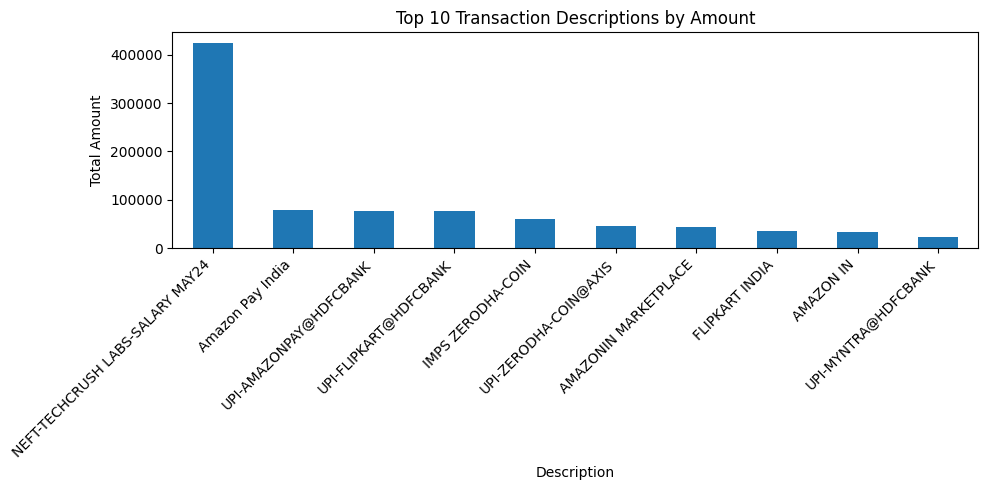

In [21]:

# Step 22: Plot top 10 descriptions by amount

top_spending.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Transaction Descriptions by Amount")
plt.xlabel("Description")
plt.ylabel("Total Amount")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [23]:

import os

print(os.listdir("/content"))


['.config', '20440378-SpendDNA_Minor_Project_Brief.zip', 'rahul_transactions.csv', 'sample_data']


In [24]:

# Step 23: Load original transaction dataset

import pandas as pd

original_df = pd.read_csv("/content/rahul_transactions.csv")

print("Original Amount values:")
print(original_df["Amount"].head(20).to_list())


Original Amount values:
['₹2462', '50.00', '₹84728', '₹1828', '270.00', 'Rs. 625', 'Rs. 148', '₹482', 'Rs. 537', '3956', '₹350', '₹311', '258.00', '₹571', '266.00', '₹405', '267.00', 'Rs. 48', '₹1411', '2,557.00']


In [25]:

# Step 24: Correct Amount cleaning

original_df["Amount"] = (
    original_df["Amount"]
    .astype(str)
    .str.replace(r"[₹,]", "", regex=True)
    .str.replace(r"Rs\.\s*", "", regex=True)
    .str.strip()
)

original_df["Amount"] = pd.to_numeric(
    original_df["Amount"], errors="coerce"
)

print(original_df["Amount"].head(20))
print("\nAmount data type:", original_df["Amount"].dtype)
print("Missing amounts:", original_df["Amount"].isnull().sum())


0      2462.0
1        50.0
2     84728.0
3      1828.0
4       270.0
5       625.0
6       148.0
7       482.0
8       537.0
9      3956.0
10      350.0
11      311.0
12      258.0
13      571.0
14      266.0
15      405.0
16      267.0
17       48.0
18     1411.0
19     2557.0
Name: Amount, dtype: float64

Amount data type: float64
Missing amounts: 0


In [26]:

# Step 25: Recreate cleaned transaction data

df = original_df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))
print("\nCorrected amount summary:")
print(df["Amount"].describe())


Rows after removing duplicates: 1310

Corrected amount summary:
count     1310.000000
mean      1670.744275
std       6306.346647
min         10.000000
25%        295.250000
50%        477.000000
75%       1009.750000
max      85492.000000
Name: Amount, dtype: float64


In [27]:

# Step 26: Transaction type analysis

df["Type"] = df["Type"].str.strip().str.upper()

df["Type"] = df["Type"].replace({
    "DR": "DEBIT",
    "CR": "CREDIT"
})

print(df.groupby("Type")["Amount"].agg(
    ["count", "sum", "mean"]
))


        count        sum          mean
Type                                  
CREDIT      6   509774.0  84962.333333
DEBIT    1304  1678901.0   1287.500767


In [28]:

# Step 27: Top 10 descriptions by total amount

top_spending = (
    df.groupby("Description")["Amount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_spending)


Description
NEFT-TECHCRUSH LABS-SALARY MAY24    509774.0
IMPS ZERODHA-COIN                    90000.0
Amazon Pay India                     87353.0
UPI-AMAZONPAY@HDFCBANK               80811.0
UPI-FLIPKART@HDFCBANK                78824.0
AMAZONIN MARKETPLACE                 66887.0
UPI-ZERODHA-COIN@AXIS                60000.0
FLIPKART INDIA                       55987.0
AMAZON IN                            41733.0
POS INDIAN OIL BANGALORE             41287.0
Name: Amount, dtype: float64


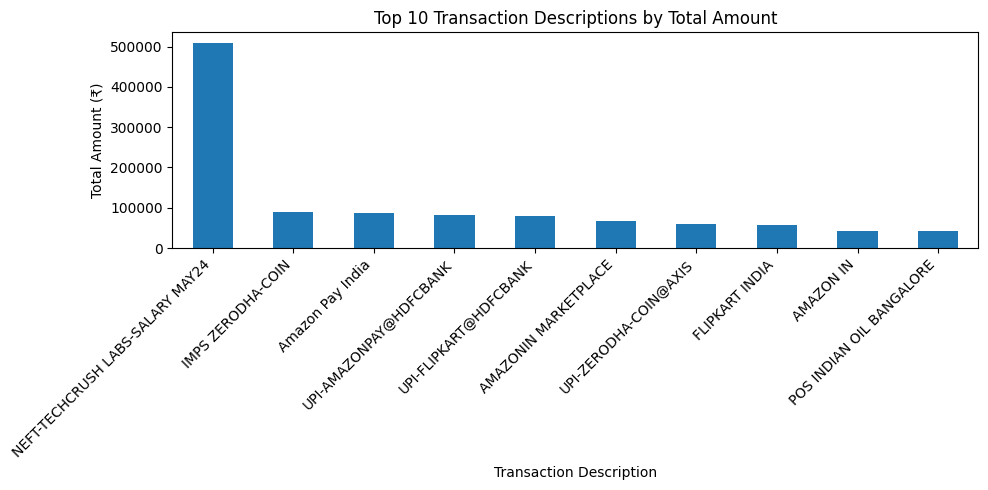

In [29]:

# Step 28: Spending chart

import matplotlib.pyplot as plt

top_spending.plot(kind="bar", figsize=(10, 5))

plt.title("Top 10 Transaction Descriptions by Total Amount")
plt.xlabel("Transaction Description")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [30]:

# Step 29: Total amount by payment mode

mode_spending = df.groupby("Mode")["Amount"].sum().sort_values(
    ascending=False
)

print("Total amount by payment mode:")
print(mode_spending)


Total amount by payment mode:
Mode
UPI     1525401.0
NEFT     509774.0
IMPS     108000.0
ATM       45500.0
Name: Amount, dtype: float64


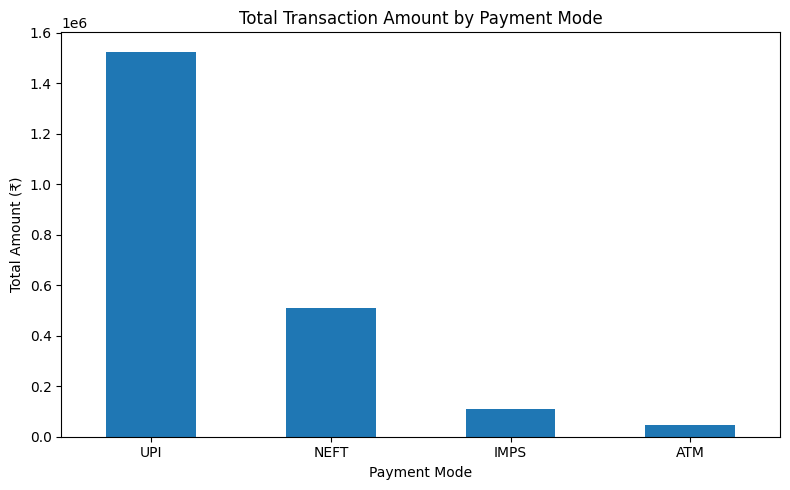

In [31]:

# Step 30: Payment mode spending chart

mode_spending.plot(kind="bar", figsize=(8, 5))

plt.title("Total Transaction Amount by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [32]:

# Step 31: Monthly transaction analysis

df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

df["Month"] = df["Date"].dt.to_period("M")

monthly_amount = df.groupby("Month")["Amount"].sum()

print("Monthly transaction amounts:")
print(monthly_amount)


Monthly transaction amounts:
Month
2024-01    185066.0
2024-02      6390.0
2024-03     26578.0
2024-04      5246.0
2024-05     21011.0
2024-06      9292.0
2024-07     23632.0
2024-08     41383.0
2024-09     14154.0
2024-10      5541.0
2024-11      6366.0
2024-12     30745.0
Freq: M, Name: Amount, dtype: float64


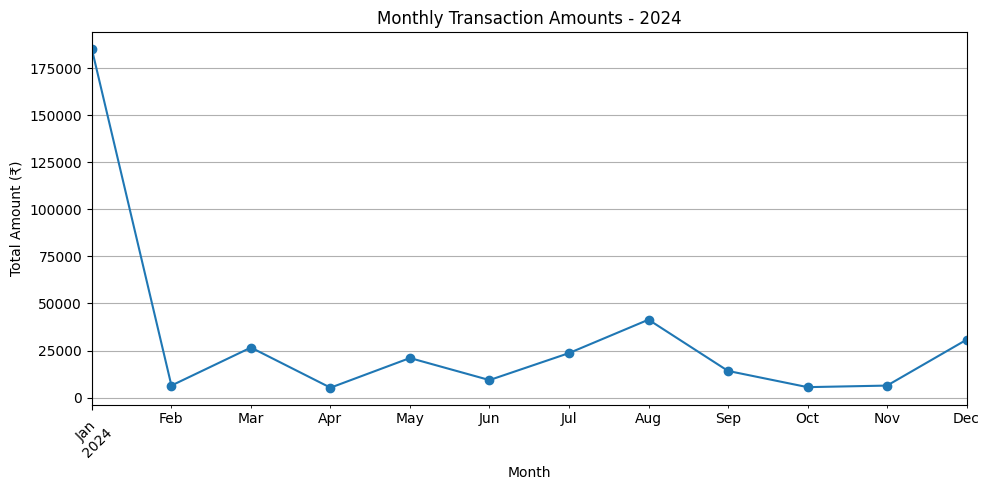

In [33]:

# Step 32: Monthly transaction line graph

monthly_amount.plot(kind="line", marker="o", figsize=(10, 5))

plt.title("Monthly Transaction Amounts - 2024")
plt.xlabel("Month")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [34]:

# Step 33: Top 10 largest transactions

top_transactions = df.nlargest(10, "Amount")[
    ["Date", "Description", "Type", "Amount", "Mode"]
]

print(top_transactions.to_string(index=False))



      Date                      Description   Type  Amount Mode
       NaT NEFT-TECHCRUSH LABS-SALARY MAY24 CREDIT 85492.0 NEFT
2024-01-05 NEFT-TECHCRUSH LABS-SALARY MAY24 CREDIT 85393.0 NEFT
       NaT NEFT-TECHCRUSH LABS-SALARY MAY24 CREDIT 84736.0 NEFT
       NaT NEFT-TECHCRUSH LABS-SALARY MAY24 CREDIT 84728.0 NEFT
       NaT NEFT-TECHCRUSH LABS-SALARY MAY24 CREDIT 84724.0 NEFT
2024-01-03 NEFT-TECHCRUSH LABS-SALARY MAY24 CREDIT 84701.0 NEFT
       NaT             AMAZONIN MARKETPLACE  DEBIT 22008.0  UPI
       NaT           UPI-AMAZONPAY@HDFCBANK  DEBIT 21986.0  UPI
       NaT           UPI-AMAZONPAY@HDFCBANK  DEBIT 19917.0  UPI
       NaT                        AMAZON IN  DEBIT 18273.0  UPI


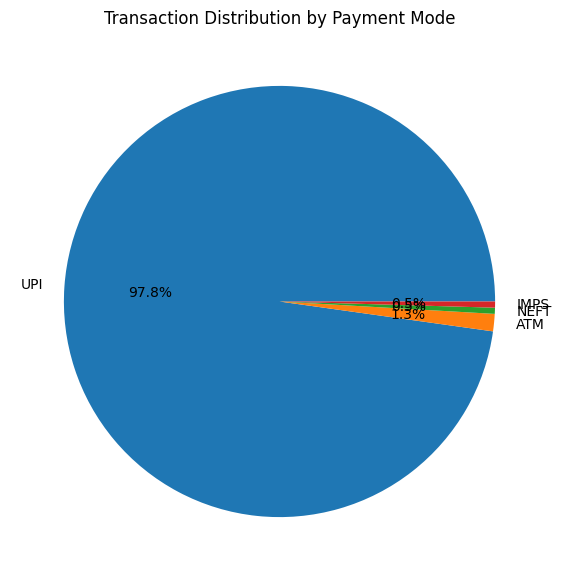

In [35]:

# Step 34: Payment mode distribution

df["Mode"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7)
)

plt.title("Transaction Distribution by Payment Mode")
plt.ylabel("")
plt.show()


In [45]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [46]:
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Rows after removing duplicates: 1310


In [47]:
print(df.dtypes)

Date           datetime64[ns]
Time                   object
Description            object
Type                   object
Amount                float64
Balance               float64
Mode                   object
Ref                    object
Month                  object
dtype: object


In [48]:
print("Missing dates:", df["Date"].isna().sum())

Missing dates: 0


In [50]:
df["Month"] = df["Date"].dt.month_name()

In [51]:
print(df.isnull().sum())

Date           0
Time           0
Description    0
Type           0
Amount         0
Balance        0
Mode           0
Ref            0
Month          0
dtype: int64


In [52]:
print(df["Type"].value_counts())

Type
DEBIT     1304
CREDIT       6
Name: count, dtype: int64


In [53]:
print(df["Amount"].describe())

count     1310.000000
mean      1670.744275
std       6306.346647
min         10.000000
25%        295.250000
50%        477.000000
75%       1009.750000
max      85492.000000
Name: Amount, dtype: float64


In [54]:
print(df.head(10))
print("Total transactions:", len(df))

        Date   Time                       Description    Type   Amount  \
0 2024-01-01  03:11                AMAZON SELLER SVCS   DEBIT   2462.0   
1 2024-01-01  05:44                         BHIM-BMTC   DEBIT     50.0   
2 2024-01-01  09:35  NEFT-TECHCRUSH LABS-SALARY MAY24  CREDIT  84728.0   
3 2024-01-01  14:07              UPI-AMAN-8934@OKAXIS   DEBIT   1828.0   
4 2024-01-01  14:23                      BHIM-BLINKIT   DEBIT    270.0   
5 2024-01-01  14:48                        BHIM ZEPTO   DEBIT    625.0   
6 2024-01-01  14:50            UPI-UBER-2426@HDFCBANK   DEBIT    148.0   
7 2024-01-01  21:44                      BHIM-BLINKIT   DEBIT    482.0   
8 2024-01-02  05:18              POS SWIGGY BANGALORE   DEBIT    537.0   
9 2024-01-02  06:55             UPI-GROWWPAY@HDFCBANK   DEBIT   3956.0   

    Balance  Mode        Ref    Month  
0  678275.0   UPI  TXN190872  January  
1  681007.0   UPI  TXN143064  January  
2  484728.0  NEFT  TXN246316  January  
3 -748745.0   UPI  TXN569

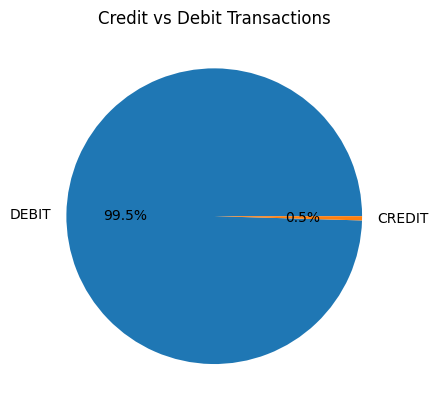

In [55]:
import matplotlib.pyplot as plt

df["Type"].value_counts().plot(
    kind="pie", autopct="%1.1f%%"
)
plt.title("Credit vs Debit Transactions")
plt.ylabel("")
plt.show()

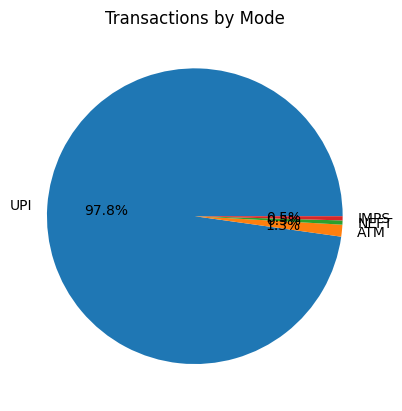

In [56]:
df["Mode"].value_counts().plot(
    kind="pie", autopct="%1.1f%%"
)
plt.title("Transactions by Mode")
plt.ylabel("")
plt.show()

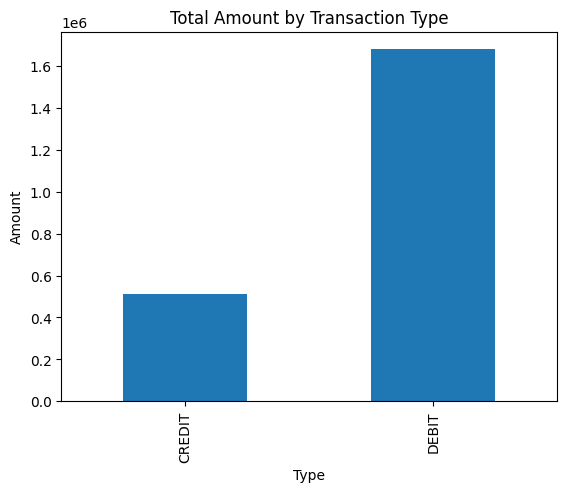

In [57]:
df.groupby("Type")["Amount"].sum().plot(kind="bar")
plt.title("Total Amount by Transaction Type")
plt.ylabel("Amount")
plt.show()

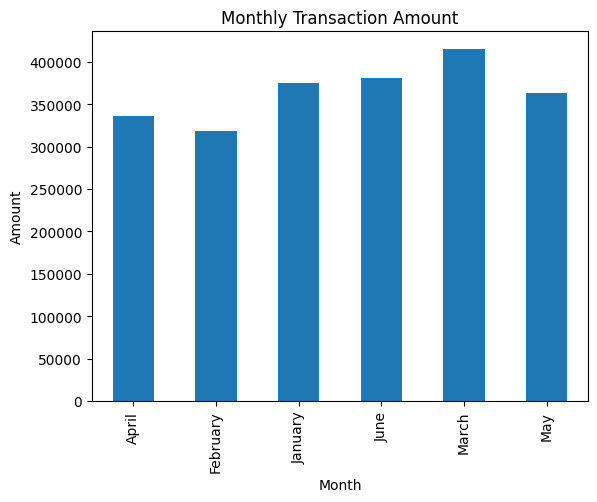

In [58]:
df.groupby("Month")["Amount"].sum().plot(kind="bar")
plt.title("Monthly Transaction Amount")
plt.ylabel("Amount")
plt.show()

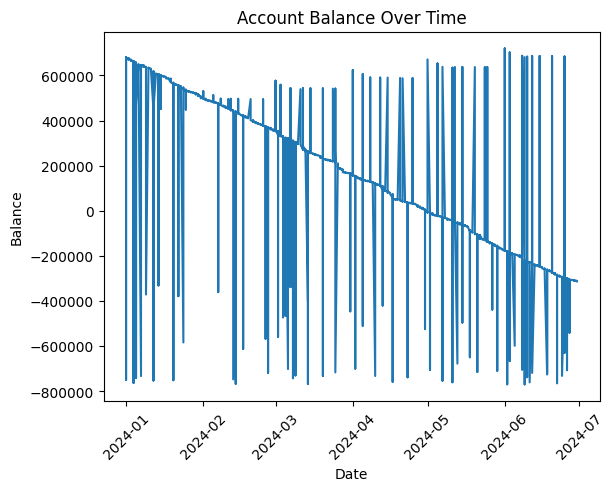

In [59]:
df = df.sort_values("Date")

plt.plot(df["Date"], df["Balance"])
plt.title("Account Balance Over Time")
plt.xlabel("Date")
plt.ylabel("Balance")
plt.xticks(rotation=45)
plt.show()

In [60]:
df.to_csv("Cleaned_Bank_Transactions.csv", index=False)

In [61]:
from google.colab import files
files.download("Cleaned_Bank_Transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
print(df.shape)
print(df.head())
print(df.columns)

(1310, 9)
        Date   Time                       Description    Type   Amount  \
0 2024-01-01  03:11                AMAZON SELLER SVCS   DEBIT   2462.0   
1 2024-01-01  05:44                         BHIM-BMTC   DEBIT     50.0   
2 2024-01-01  09:35  NEFT-TECHCRUSH LABS-SALARY MAY24  CREDIT  84728.0   
3 2024-01-01  14:07              UPI-AMAN-8934@OKAXIS   DEBIT   1828.0   
4 2024-01-01  14:23                      BHIM-BLINKIT   DEBIT    270.0   

    Balance  Mode        Ref    Month  
0  678275.0   UPI  TXN190872  January  
1  681007.0   UPI  TXN143064  January  
2  484728.0  NEFT  TXN246316  January  
3 -748745.0   UPI  TXN569226  January  
4  680737.0   UPI  TXN968962  January  
Index(['Date', 'Time', 'Description', 'Type', 'Amount', 'Balance', 'Mode',
       'Ref', 'Month'],
      dtype='object')


In [63]:
print(df.groupby("Type")["Amount"].sum())

Type
CREDIT     509774.0
DEBIT     1678901.0
Name: Amount, dtype: float64


In [64]:
print(df.loc[df["Amount"].idxmax()])

Date                        2024-06-01 00:00:00
Time                                      09:31
Description    NEFT-TECHCRUSH LABS-SALARY MAY24
Type                                     CREDIT
Amount                                  85492.0
Balance                                720079.0
Mode                                       NEFT
Ref                                   TXN399607
Month                                      June
Name: 1113, dtype: object


In [65]:
print(df.loc[df["Amount"].idxmin()])

Date           2024-02-16 00:00:00
Time                         07:40
Description              BHIM-BMTC
Type                         DEBIT
Amount                        10.0
Balance                   424326.0
Mode                           UPI
Ref                      TXN139589
Month                     February
Name: 328, dtype: object


In [66]:
print("Total transactions:", len(df))
print("Total credit:", df.loc[df["Type"] == "CREDIT", "Amount"].sum())
print("Total debit:", df.loc[df["Type"] == "DEBIT", "Amount"].sum())
print("Average amount:", df["Amount"].mean())

Total transactions: 1310
Total credit: 509774.0
Total debit: 1678901.0
Average amount: 1670.7442748091603


In [67]:
df.to_csv("Final_Bank_Transactions.csv", index=False)

In [68]:
from google.colab import files
files.download("Final_Bank_Transactions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [69]:
monthly = df.groupby("Month")["Amount"].sum()
print(monthly)

Month
April       336118.0
February    318795.0
January     375495.0
June        380409.0
March       415159.0
May         362699.0
Name: Amount, dtype: float64


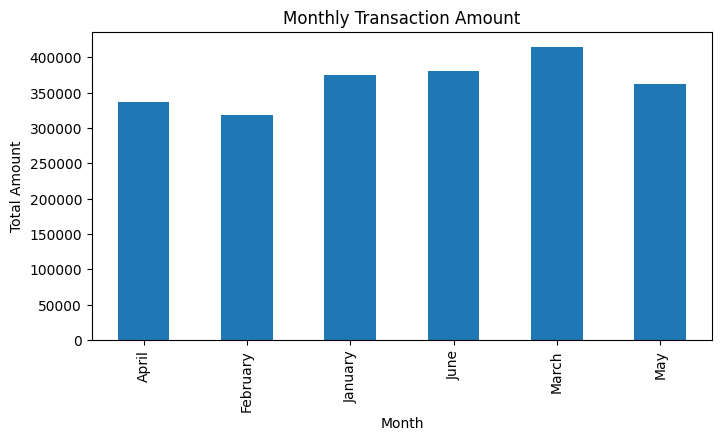

In [70]:
monthly.plot(kind="bar", figsize=(8, 4))
plt.title("Monthly Transaction Amount")
plt.xlabel("Month")
plt.ylabel("Total Amount")
plt.show()

In [71]:
print(df["Type"].value_counts())

Type
DEBIT     1304
CREDIT       6
Name: count, dtype: int64


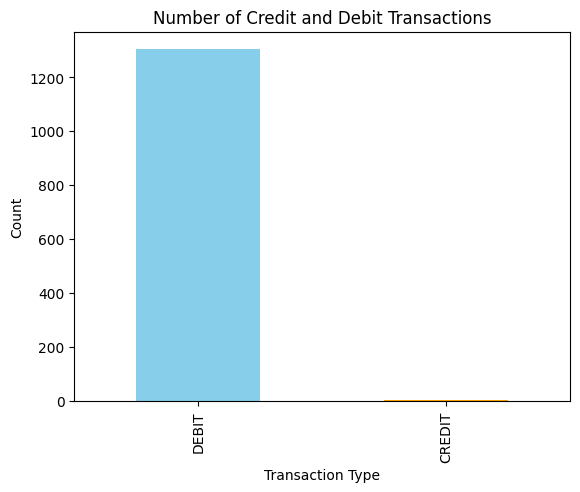

In [72]:
df["Type"].value_counts().plot(
    kind="bar", color=["skyblue", "orange"]
)
plt.title("Number of Credit and Debit Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

In [73]:
print(df["Mode"].value_counts())

Mode
UPI     1281
ATM       17
NEFT       6
IMPS       6
Name: count, dtype: int64


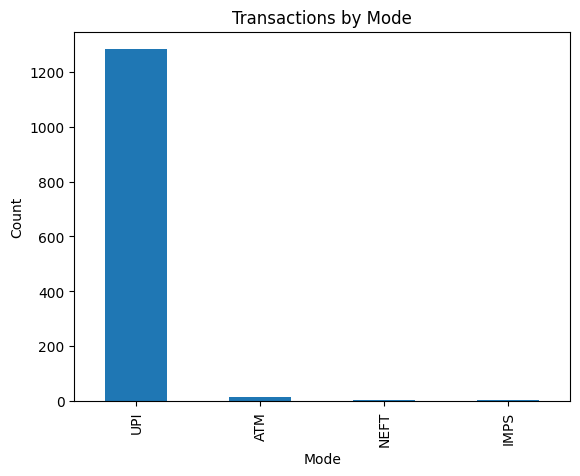

In [74]:
df["Mode"].value_counts().plot(kind="bar")
plt.title("Transactions by Mode")
plt.xlabel("Mode")
plt.ylabel("Count")
plt.show()

In [75]:
df.groupby("Mode")["Amount"].agg(
    ["count", "sum", "mean"]
).to_csv("Transaction_Mode_Summary.csv")

In [76]:
print(df["Mode"].value_counts().idxmax())

UPI


In [77]:
print(df.groupby("Month")["Amount"].sum().idxmax())

March


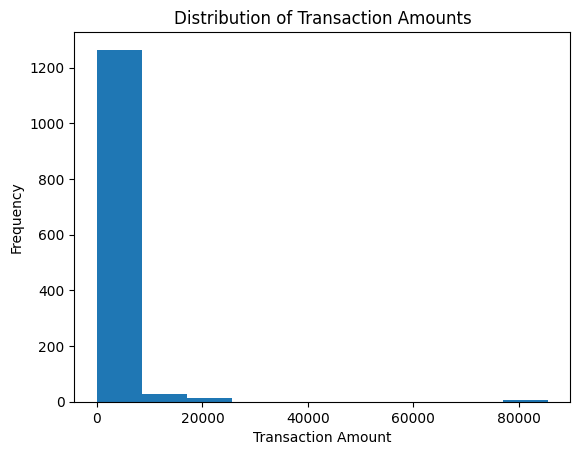

In [78]:
import matplotlib.pyplot as plt

plt.hist(df["Amount"], bins=10)
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

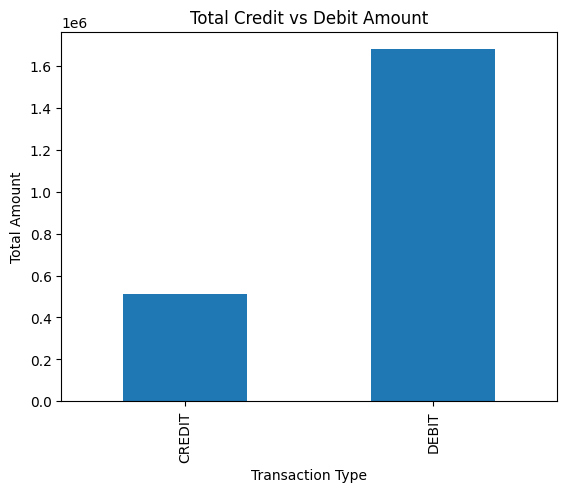

In [79]:
df.groupby("Type")["Amount"].sum().plot(kind="bar")
plt.title("Total Credit vs Debit Amount")
plt.xlabel("Transaction Type")
plt.ylabel("Total Amount")
plt.show()

In [80]:
summary = df.groupby("Type")["Amount"].agg(["count", "sum", "mean"])
summary.to_csv("Final_Transaction_Summary.csv")
print(summary)

        count        sum          mean
Type                                  
CREDIT      6   509774.0  84962.333333
DEBIT    1304  1678901.0   1287.500767


In [81]:
print("Total Transactions:", len(df))
print("Most Used Mode:", df["Mode"].mode()[0])
print("Most Common Type:", df["Type"].mode()[0])
print("Highest Transaction:", df["Amount"].max())
print("Lowest Transaction:", df["Amount"].min())
print("Average Transaction:", round(df["Amount"].mean(), 2))

Total Transactions: 1310
Most Used Mode: UPI
Most Common Type: DEBIT
Highest Transaction: 85492.0
Lowest Transaction: 10.0
Average Transaction: 1670.74


In [82]:
summary = pd.DataFrame({
    "Metric": [
        "Total Transactions",
        "Most Used Mode",
        "Most Common Type",
        "Highest Transaction",
        "Lowest Transaction",
        "Average Transaction"
    ],
    "Result": [
        len(df),
        df["Mode"].mode()[0],
        df["Type"].mode()[0],
        df["Amount"].max(),
        df["Amount"].min(),
        round(df["Amount"].mean(), 2)
    ]
})

print(summary)
summary.to_csv("Final_Project_Results.csv", index=False)

                Metric   Result
0   Total Transactions     1310
1       Most Used Mode      UPI
2     Most Common Type    DEBIT
3  Highest Transaction  85492.0
4   Lowest Transaction     10.0
5  Average Transaction  1670.74


In [83]:
from google.colab import files
files.download("Final_Project_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [84]:
print(summary)
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

                Metric   Result
0   Total Transactions     1310
1       Most Used Mode      UPI
2     Most Common Type    DEBIT
3  Highest Transaction  85492.0
4   Lowest Transaction     10.0
5  Average Transaction  1670.74
Total rows: 1310
Total columns: 9


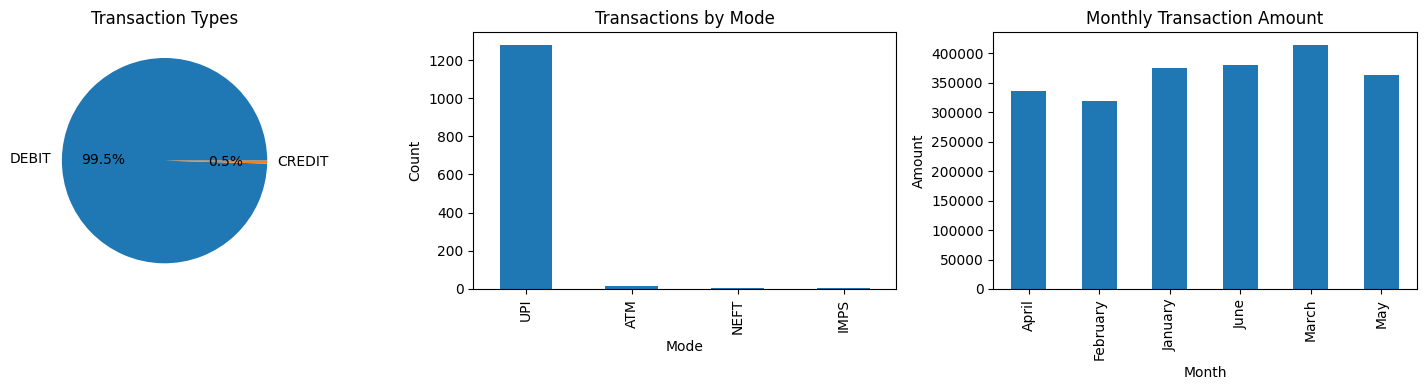

In [85]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df["Type"].value_counts().plot(
    kind="pie", autopct="%1.1f%%", ax=ax[0]
)
ax[0].set_title("Transaction Types")
ax[0].set_ylabel("")

df["Mode"].value_counts().plot(
    kind="bar", ax=ax[1]
)
ax[1].set_title("Transactions by Mode")
ax[1].set_ylabel("Count")

df.groupby("Month")["Amount"].sum().plot(
    kind="bar", ax=ax[2]
)
ax[2].set_title("Monthly Transaction Amount")
ax[2].set_ylabel("Amount")

plt.tight_layout()
plt.show()

In [86]:
fig.savefig("Bank_Transaction_Dashboard.png", dpi=300)

In [87]:
from google.colab import files
files.download("Bank_Transaction_Dashboard.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>